# Ising spin-configuration heatmap

# One-dimensional Ising model — Metropolis Monte Carlo

We simulate the classical 1D Ising model with periodic boundary conditions,

$$H=-J\sum_{i=1}^{N}s_i s_{i+1},\qquad s_i\in\{-1,+1\},\quad s_{N+1}=s_1.$$

At each Monte Carlo step, **one spin flip is attempted**. A move with energy change $\Delta E$ is accepted with probability $\min(1,e^{-\Delta E/(k_B T)})$. If rejected, the configuration remains unchanged. The x-axis counts *attempted* flips, not physical time. The initial state is fully aligned ($s_i=+1$).

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def ising_energy(spins, J=1.0):
    """1D nearest-neighbor Ising energy with periodic boundary conditions."""
    return -J * np.sum(spins * np.roll(spins, -1))


def metropolis_step(spins, energy, rng, temperature, J=1.0, k_B=1.0):
    """Attempt exactly one spin flip; rejected moves retain the old state."""
    i = rng.integers(len(spins))
    left = spins[(i - 1) % len(spins)]
    right = spins[(i + 1) % len(spins)]
    delta_e = 2.0 * J * spins[i] * (left + right)
    accepted = delta_e <= 0 or rng.random() < np.exp(-delta_e / (k_B * temperature))
    if accepted:
        spins[i] *= -1
        energy += delta_e
    return energy, accepted


## Simulate and record spin configurations

Every attempted spin flip produces one row in the history, including rejected proposals.

In [2]:
N = 30
n_steps = 500
J = 1.0
k_B = 1.0
T = 1.0
seed = 42

rng = np.random.default_rng(seed)
spins = np.ones(N, dtype=int)
energy = ising_energy(spins, J)
history = np.empty((n_steps + 1, N), dtype=int)
history[0] = spins
accepted_count = 0

for step in range(1, n_steps + 1):
    energy, accepted = metropolis_step(spins, energy, rng, T, J, k_B)
    history[step] = spins
    accepted_count += accepted

print(f"Final energy: {energy:.1f}")
print(f"Acceptance rate: {accepted_count/n_steps:.1%}")
assert np.isclose(energy, ising_energy(spins, J))

Final energy: -26.0
Acceptance rate: 14.8%


## Spin-configuration heatmap

Blue represents spin $-1$ and red represents spin $+1$. The rows show Monte Carlo steps; the columns show spin sites.

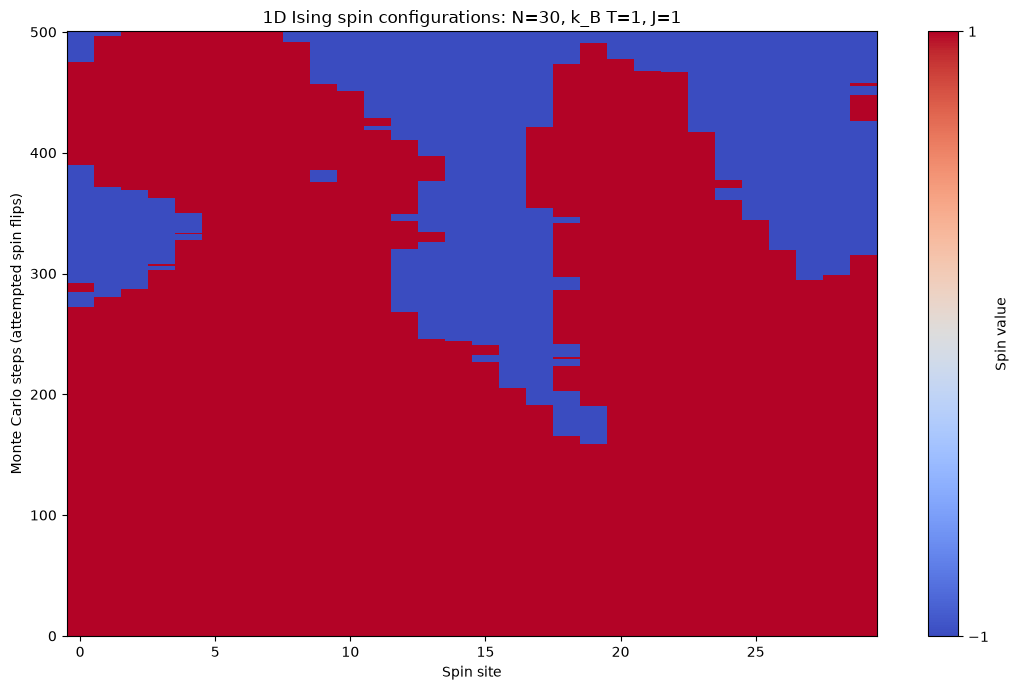

In [3]:
plt.figure(figsize=(11, 7))
plt.imshow(history, aspect="auto", origin="lower", interpolation="nearest",
           cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(ticks=[-1, 1], label="Spin value")
plt.xlabel("Spin site")
plt.ylabel("Monte Carlo steps (attempted spin flips)")
plt.title(f"1D Ising spin configurations: N={N}, k_B T={k_B*T:g}, J={J:g}")
plt.tight_layout()
plt.show()

## Quick correctness checks

In [4]:
assert history.shape == (n_steps + 1, N)
assert np.all(np.isin(history, [-1, 1]))
assert np.all(np.sum(history[1:] != history[:-1], axis=1) <= 1)
print("Spin values and single-flip transition checks passed.")

Spin values and single-flip transition checks passed.
